# 三角涡量初值：粗步长行为与时间收敛

本批次是无滑移加权三角涡量初值和 $f=(\cos x,0)$。保留普通格式失败及巨大有限误差，不将 SAV 的有界结果等同于粗步准确。

[中文论文描述](description.tex) · [输入与执行](README.md)

In [1]:
from pathlib import Path
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'pyproject.toml').is_file())
REPORT_DIRECTORY = Path('reports/trig_ns_convergence/20260922T054144-5aee3c91')
EXPECTED_ANALYSIS_SHA256 = '34c7900476f3ebdac63ed230c75adb43e71e8a671f249605aa6e0ac8f457ecce'
EXPECTED_TABLE_SHA256 = '16f4b36a1ce2a2fd4806ac6e6de8cd44bd97487dad47903c7e4ff8b85367e47b'

## 输入与限制
只展示下面显式报告及其保存误差表；不选择最新运行、不推进求解器、不重算场误差。
执行时校验报告、表格、捕获批次和全部被测/参考记录，以及完成状态与观测时刻。
历史路径只按捕获的实验名和运行编号迁移到 `PROJECT_ROOT/runs/`，不搜索替代运行。
失败运行留在表内，图底部的叉号仅表示失败步长，不代表一个数值误差。
$H^1$ 列是离散黏性二次型定义的半范数，不是压力误差。

In [2]:
import sys, json, math
from html import escape
sys.path.insert(0, str(PROJECT_ROOT))
from experiments.study_data import read_reference_study
from experiments.plotting import reference_error_figure
from IPython.display import display, HTML
import matplotlib.pyplot as plt
%matplotlib inline
report = PROJECT_ROOT/REPORT_DIRECTORY
batch, physical, rows = read_reference_study(
    PROJECT_ROOT, report, analysis_sha256=EXPECTED_ANALYSIS_SHA256,
    table_sha256=EXPECTED_TABLE_SHA256)
analysis = json.loads((report/'analysis.json').read_text())
print('Captured batch:', Path(analysis['batch']).parent.name)
print('Historical solver source:', batch['source']['code_sha256'])
print('Recorded physical settings:', json.dumps({k: physical.get(k) for k in
      ('experiment', 'nx', 'ny', 'lx', 'ly', 'nu', 'gamma', 'T', 'force', 'initial_condition', 'boundary')}, ensure_ascii=False))
print('Trial runs:', len(batch['trials']), '; failed trial rows:', sum(r['status']=='failed' for r in rows))

Captured batch: 20260922T050733-f2dbf5c7
Historical solver source: 5687e30833bf207de0f6e630a4c8fdfe2b4f70d95a151597565100cafb2106c1
Recorded physical settings: {"experiment": "trig_ns", "nx": 256, "ny": 256, "lx": 6.283185307179586, "ly": 6.283185307179586, "nu": 0.001, "gamma": 5.0, "T": 4.0, "force": "[amplitude*cos(x), 0]", "initial_condition": "weighted_trig_vorticity", "boundary": "homogeneous_no_slip"}
Trial runs: 18 ; failed trial rows: 15


## 全步长区间
所有保存层均保留。失败或缺失误差使折线断开，不跨过失败层连线；极大但有限的误差也不删除。
灰色虚线仅为二阶斜率导线，不是对全区间的拟合或稳定性证明。

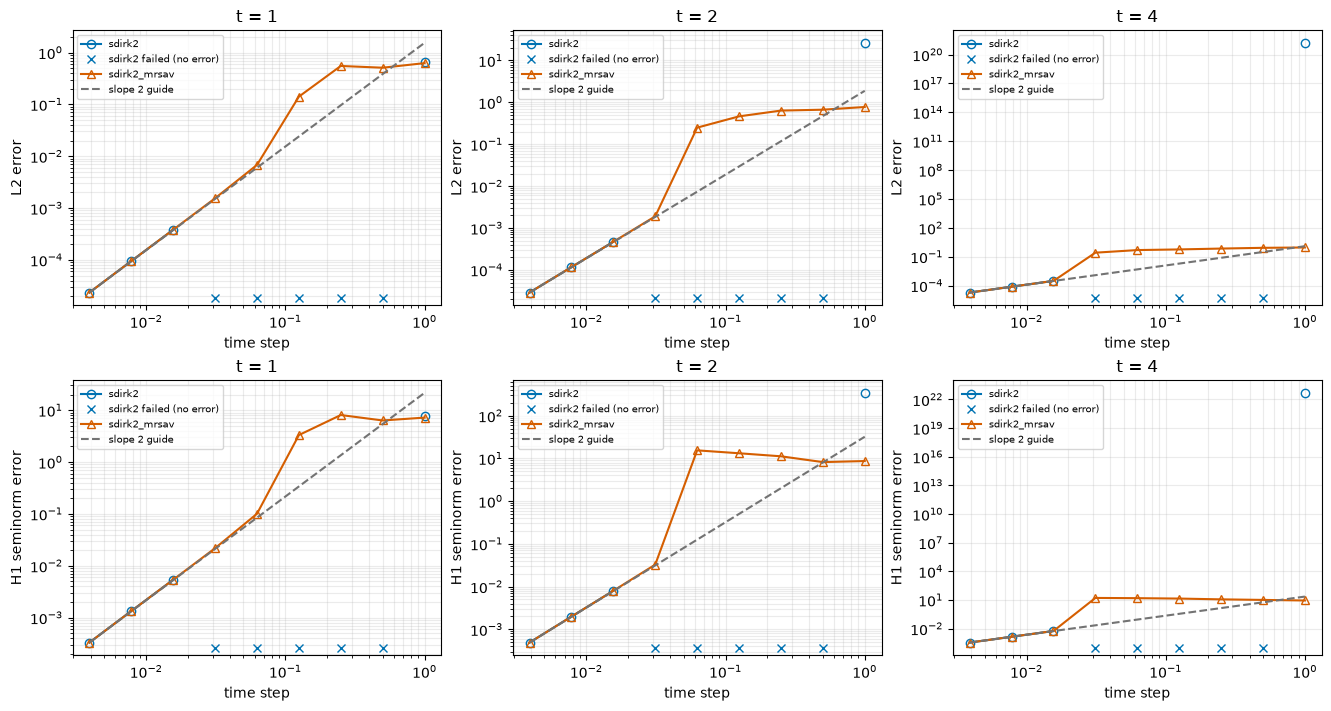

In [3]:
figure = reference_error_figure(rows)
display(figure)
plt.close(figure)

## 细步长放大（$k\geq6$）
固定展示后三个整数层的局部形态，不替代全区间图，也不把这一区间的阶数推广到粗步长。

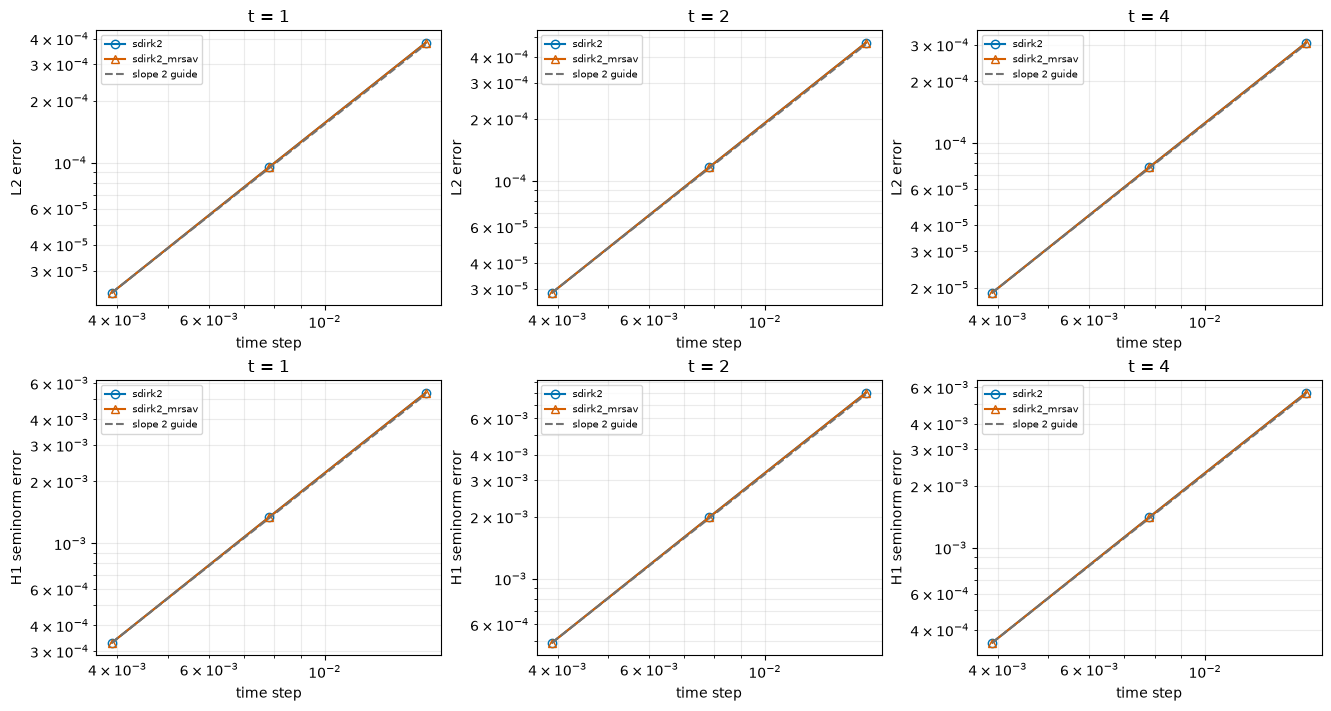

In [4]:
fine_rows = [row for row in rows if float(row['k']) >= 6]
if fine_rows:
    figure = reference_error_figure(fine_rows)
    display(figure)
    plt.close(figure)

## 完整保存误差与观察阶
`NaN` 原样保留；`failed` 不作为有限误差点绘制。观察阶来自保存表，只有相邻层误差有效时才有数值。
图中的局部阶数不能替代参考充分性或空间收敛验证。

In [5]:
columns = ('time', 'k', 'dt', 'scheme', 'status', 'L2', 'H1', 'L2_rate', 'H1_rate')
def format_cell(row, key):
    value = row[key]
    if key in ('L2', 'H1', 'dt'):
        number = float(value)
        return f'{number:.3e}' if math.isfinite(number) else 'NaN'
    return escape(str(value))
body = ''.join('<tr>'+''.join('<td>'+format_cell(row, key)+'</td>' for key in columns)+'</tr>' for row in rows)
display(HTML('<table><thead><tr>'+''.join('<th>'+key+'</th>' for key in columns)+'</tr></thead><tbody>'+body+'</tbody></table>'))

time,k,dt,scheme,status,L2,H1,L2_rate,H1_rate
1.0,0,1.000e+00,sdirk2,complete,6.684e-01,7.695e+00,nan,nan
1.0,1,5.000e-01,sdirk2,failed,1.760e+00,2.240e+01,-1.3966702127344375,-1.5414800503278068
1.0,2,2.500e-01,sdirk2,failed,1.547e+00,2.308e+01,0.1861068090894169,-0.043062189681584165
1.0,3,1.250e-01,sdirk2,failed,1.410e-01,3.318e+00,3.455559624461027,2.7982547820701202
1.0,4,6.250e-02,sdirk2,failed,6.793e-03,1.008e-01,4.375617060281092,5.041085827404924
1.0,5,3.125e-02,sdirk2,failed,1.546e-03,2.183e-02,2.135270193418604,2.2067644867799285
1.0,6,1.562e-02,sdirk2,complete,3.821e-04,5.377e-03,2.0167811305868852,2.021487562669732
1.0,7,7.812e-03,sdirk2,complete,9.504e-05,1.338e-03,2.007176454853978,2.0069662897349785
1.0,8,3.906e-03,sdirk2,complete,2.347e-05,3.304e-04,2.017745288476204,2.0174334493526893
1.0,0,1.000e+00,sdirk2_mrsav,complete,6.243e-01,7.203e+00,nan,nan


## 保存的参考敏感性检查
共同 SDIRK2 参考与再细一层参考的差，除以同一观测时刻/范数下最小有效被测误差。
所有项须不超过批次指定阈值；通过仅表示这次细化对的敏感性检查通过，不是严格误差上界。
本展示核对保存输入完整性并呈现原检查，不独立从场数据重算误差。

In [6]:
print('Reference level:', batch['references']['reference_k'])
print('Sensitivity threshold:', batch['config']['sensitivity_threshold'])
display(HTML('<pre>'+escape(json.dumps(analysis['reference_checks'], indent=2))+'</pre>'))

Reference level: 11
Sensitivity threshold: 0.05
